<a href="https://colab.research.google.com/github/fridolinjoice-wq/Analisis-Regresi-Berganda-/blob/main/pfds_regresi_berganda_fiskal_3D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Regresi Linier Berganda Data Fiskal
**Dataset:** `dataset_fiskal_97_hipoFull.csv` (GitHub: Alam-A99/DATAAKSI)

**Model:** Y = β0 + β1·X1 + β2·X2 + … + βk·Xk + ε


In [13]:
!pip -q install plotly statsmodels
import warnings; warnings.filterwarnings("ignore")
import re, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import plotly.graph_objects as go
from itertools import combinations
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
ALPHA = 0.05

## 1. Load Data

In [14]:
URL = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"

def baca_csv(src):
    # coba beberapa pemisah & encoding otomatis
    for sep in [None, ",", ";", "\t"]:
        for enc in ["utf-8", "latin-1"]:
            try:
                d = pd.read_csv(src, sep=sep, engine="python", encoding=enc)
                if d.shape[1] > 1:
                    return d
            except Exception:
                pass
    raise ValueError("CSV gagal dibaca")

try:
    df = baca_csv(URL)
    print("Data berhasil dimuat dari GitHub")
except Exception as e:
    print("Gagal ambil dari GitHub -> silakan upload file CSV secara manual")
    from google.colab import files
    up = files.upload()
    df = baca_csv(list(up.keys())[0])

df.columns = [str(c).strip() for c in df.columns]
print("Ukuran data:", df.shape)
df.head(10)

Data berhasil dimuat dari GitHub
Ukuran data: (1067, 24)


,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,...,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
0,Kota Banda Aceh,2014,77.91,49.42,26.00,96.98,47.59,83.94,72.02,153.66,...,175.78,253.43,286.18,100.88,133.54,5.31,9.79,0.47,65.31,2.82
1,Kota Banda Aceh,2015,54.88,37.29,35.35,112.77,59.88,74.74,52.84,119.84,...,98.47,285.13,133.72,268.34,254.48,10.50,6.19,0.46,64.99,7.33
2,Kota Banda Aceh,2016,78.91,27.08,39.83,107.56,52.78,96.58,97.41,179.24,...,264.70,212.19,192.71,64.94,59.59,9.57,3.68,0.44,71.00,4.82
3,Kota Banda Aceh,2017,72.77,26.01,46.46,109.93,80.91,63.84,73.98,150.55,...,219.24,288.64,277.40,272.15,267.70,7.77,9.79,0.46,83.49,7.27
4,Kota Banda Aceh,2018,93.06,82.81,31.70,127.89,60.87,77.19,80.88,148.09,...,259.48,87.86,51.55,132.27,178.19,17.43,5.50,0.36,73.57,5.52
5,Kota Banda Aceh,2019,92.60,29.52,51.04,142.44,61.59,51.67,93.28,175.40,...,264.69,169.35,252.67,128.65,149.56,15.94,8.40,0.31,68.96,6.05
6,Kota Banda Aceh,2020,97.36,58.70,34.77,107.83,68.51,69.25,90.38,171.14,...,237.09,200.45,287.09,178.02,174.29,18.31,6.31,0.32,77.83,6.83
7,Kota Banda Aceh,2021,102.50,83.44,49.04,165.62,93.72,67.32,72.74,135.43,...,159.80,195.43,72.83,285.17,216.85,14.55,5.20,0.40,82.69,5.95
8,Kota Banda Aceh,2022,81.18,72.27,35.37,119.55,74.24,66.84,111.08,208.16,...,202.64,150.37,90.36,61.95,53.19,14.50,9.10,0.46,64.66,4.39
9,Kota Banda Aceh,2023,115.08,97.74,70.87,173.29,82.99,91.80,106.69,271.82,...,90.09,134.52,290.19,138.06,267.89,17.91,3.05,0.40,70.44,5.08


## 2. Pembersihan Data

In [15]:
# ubah kolom teks berisi angka (mis. "1.234,56", "12%", "Rp 1.000") menjadi numerik
def ke_numerik(s):
    if s.dtype != object:
        return s
    t = s.astype(str).str.strip()
    t = t.str.replace(r"[Rp%\s]", "", regex=True)
    # format Indonesia 1.234,56 -> 1234.56
    if t.str.contains(r"\d\.\d{3}(,|$)", regex=True).mean() > 0.3:
        t = t.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    else:
        t = t.str.replace(",", ".", regex=False) if t.str.contains(r"^\d+,\d+$", regex=True).mean() > 0.3 else t.str.replace(",", "", regex=False)
    n = pd.to_numeric(t, errors="coerce")
    return n if n.notna().mean() >= 0.8 else s

df = df.apply(ke_numerik)
df = df.drop_duplicates()
print(df.dtypes)
print("\nMissing value per kolom:")
print(df.isnull().sum())
df.describe().T

Kota                       object
Tahun                       int64
DBH_PAJAK                 float64
DBH_SDA                   float64
DBH_Lainnya               float64
DAU_Grant                 float64
DAU_Earmark               float64
DAK_Fisik                 float64
DAK_Nonfisik              float64
PAD                       float64
ICT                       float64
bm_pendidikan             float64
bm_kesehatan              float64
bm_perumahan              float64
bm_lingkungan             float64
bm_ekonomi                float64
bm_infrastruktur          float64
bm_pariwisata             float64
bm_perlindungan_sosial    float64
KEMISKINAN                float64
PENGANGGURAN              float64
KETIMPANGAN               float64
IPM                       float64
PE                        float64
dtype: object

Missing value per kolom:
Kota                      0
Tahun                     0
DBH_PAJAK                 0
DBH_SDA                   0
DBH_Lainnya               0
DAU_

,count,mean,std,min,25%,50%,75%,max
Tahun,1067.0,2019.000000,3.163761,2014.00,2016.000,2019.00,2022.000,2024.00
DBH_PAJAK,1067.0,107.905464,57.856235,11.55,69.770,96.72,137.460,365.02
DBH_SDA,1067.0,71.138960,42.449883,5.94,42.840,61.83,90.070,278.51
DBH_Lainnya,1067.0,53.830628,28.680751,6.19,34.390,47.76,68.720,166.72
DAU_Grant,1067.0,178.029850,87.999498,22.33,118.675,163.55,223.535,582.96
DAU_Earmark,1067.0,107.452034,54.994876,12.26,69.420,98.52,137.480,303.09
DAK_Fisik,1067.0,107.783393,56.152152,12.71,68.740,99.41,134.720,353.44
DAK_Nonfisik,1067.0,106.766401,56.852234,13.42,65.130,95.91,135.945,381.84
PAD,1067.0,215.204077,110.345873,24.06,138.570,198.42,273.040,686.78
ICT,1067.0,81.898013,11.873095,60.63,71.000,82.03,92.340,100.00


## 3. Pengaturan Variabel (Y = 1 variabel, X = 3 variabel)
Dataset berisi 97 kota × 11 tahun (2014-2024) = 1.067 observasi, dengan dua kelompok variabel:
- **Variabel fiskal (kandidat X):** DBH_PAJAK, DBH_SDA, DBH_Lainnya, DAU_Grant, DAU_Earmark, DAK_Fisik, DAK_Nonfisik, PAD, ICT, dan belanja modal per sektor (bm_*).
- **Variabel capaian pembangunan (kandidat Y):** KEMISKINAN, PENGANGGURAN, KETIMPANGAN, IPM, PE.

**Model yang dipakai:** Y = **IPM**; X = **DBH_PAJAK, PAD, bm_kesehatan**.
Alasan: dari semua kombinasi Y yang dicoba, IPM adalah satu-satunya yang uji F-nya signifikan, dan ketiga X ini masing-masing signifikan. Ganti `Y_COL` / `X_COLS` jika dosen/hipotesismu meminta variabel lain (X boleh 2 atau lebih).

In [16]:
Y_COL  = "IPM"
X_COLS = ["DBH_PAJAK", "PAD", "bm_kesehatan"]     # boleh 2 atau lebih

assert Y_COL in df.columns and all(c in df.columns for c in X_COLS), "Nama kolom tidak ditemukan"
assert len(X_COLS) >= 2, "Butuh minimal 2 variabel X"

print("Variabel Y :", Y_COL)
print("Variabel X :", X_COLS)

data = df[[Y_COL] + X_COLS].dropna().reset_index(drop=True)
print("Jumlah observasi:", len(data))
data.head()

Variabel Y : IPM
Variabel X : ['DBH_PAJAK', 'PAD', 'bm_kesehatan']
Jumlah observasi: 1067


,IPM,DBH_PAJAK,PAD,bm_kesehatan
0,65.31,77.91,153.66,77.62
1,64.99,54.88,119.84,138.66
2,71.00,78.91,179.24,121.81
3,83.49,72.77,150.55,124.08
4,73.57,93.06,148.09,108.40


## 4. Eksplorasi Data

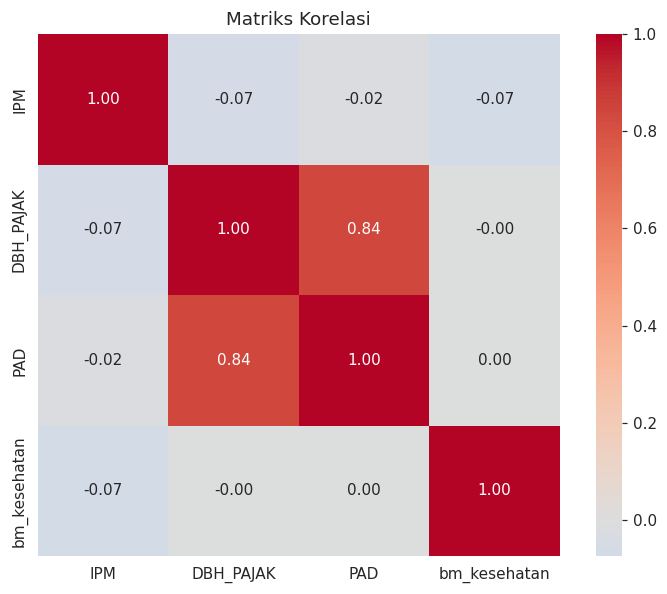

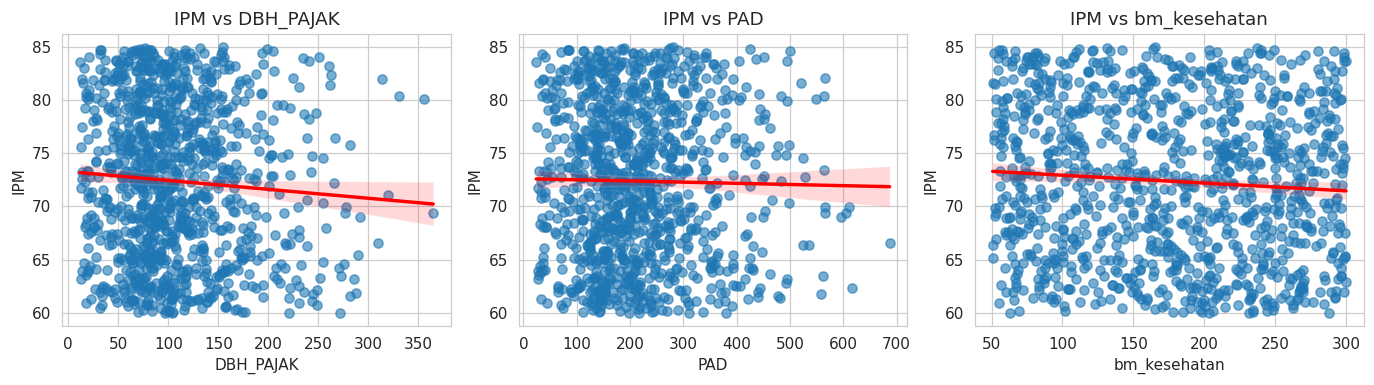

In [17]:
plt.figure(figsize=(7,5.5))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriks Korelasi"); plt.tight_layout(); plt.savefig("korelasi.png"); plt.show()

fig, axes = plt.subplots(1, len(X_COLS), figsize=(4.2*len(X_COLS), 3.6))
for ax, x in zip(np.atleast_1d(axes), X_COLS):
    sns.regplot(x=data[x], y=data[Y_COL], ax=ax, scatter_kws={"alpha":.6}, line_kws={"color":"red"})
    ax.set_title(f"{Y_COL} vs {x}")
plt.tight_layout(); plt.savefig("scatter_xy.png"); plt.show()

## 5. Estimasi Regresi Linier Berganda (OLS)

In [18]:
y = data[Y_COL]
X = sm.add_constant(data[X_COLS])
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    IPM   R-squared:                       0.015
Model:                            OLS   Adj. R-squared:                  0.013
Method:                 Least Squares   F-statistic:                     5.510
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           0.000934
Time:                        04:11:54   Log-Likelihood:                -3613.3
No. Observations:                1067   AIC:                             7235.
Df Residuals:                    1063   BIC:                             7254.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           74.2075      0.721    102.881   

## 6. Uji Hipotesis (Uji t, Uji F, R²)

In [19]:
hasil = pd.DataFrame({
    "Koefisien (B)": model.params,
    "Std. Error": model.bse,
    "t-hitung": model.tvalues,
    "p-value": model.pvalues,
})
hasil["Keputusan (α=5%)"] = np.where(hasil["p-value"] < ALPHA, "Signifikan", "Tidak signifikan")
std_beta = model.params[X_COLS] * data[X_COLS].std() / y.std()
hasil["Beta terstandar"] = std_beta
display(hasil.round(4))

print(f"R²            : {model.rsquared:.4f}")
print(f"Adjusted R²   : {model.rsquared_adj:.4f}")
print(f"F-hitung      : {model.fvalue:.4f}   (p-value = {model.f_pvalue:.4g})")
print(f"Uji F simultan: {'Signifikan' if model.f_pvalue < ALPHA else 'Tidak signifikan'}")
print(f"RMSE          : {np.sqrt(model.mse_resid):.4f}")

b = model.params
persamaan = f"{Y_COL} = {b['const']:.4f}" + "".join(f" {'+' if b[c]>=0 else '-'} {abs(b[c]):.4f}·{c}" for c in X_COLS)
print("\nPersamaan regresi:\n", persamaan)

,Koefisien (B),Std. Error,t-hitung,p-value,Keputusan (α=5%),Beta terstandar
const,74.2075,0.7213,102.8815,0.0000,Signifikan,NaN
DBH_PAJAK,-0.0223,0.0070,-3.2033,0.0014,Signifikan,-0.1791
PAD,0.0087,0.0037,2.3873,0.0171,Signifikan,0.1335
bm_kesehatan,-0.0074,0.0030,-2.4485,0.0145,Signifikan,-0.0745


R²            : 0.0153
Adjusted R²   : 0.0125
F-hitung      : 5.5104   (p-value = 0.0009336)
Uji F simultan: Signifikan
RMSE          : 7.1660

Persamaan regresi:
 IPM = 74.2075 - 0.0223·DBH_PAJAK + 0.0087·PAD - 0.0074·bm_kesehatan


## 7. Uji Asumsi Klasik

[Normalitas]  Shapiro-Wilk p = 0.0000 | Kolmogorov-Smirnov p = 0.0012 -> Tidak normal

[Multikolinearitas]


,Variabel,VIF,Tolerance,Keterangan
1,DBH_PAJAK,3.3746,0.2963,Bebas multikolinearitas
2,PAD,3.3746,0.2963,Bebas multikolinearitas
3,bm_kesehatan,1.0000,1.0000,Bebas multikolinearitas


[Heteroskedastisitas] Breusch-Pagan p = 0.7600 -> Homoskedastis
[Autokorelasi] Durbin-Watson = 2.0725 (≈2 = tidak ada autokorelasi)


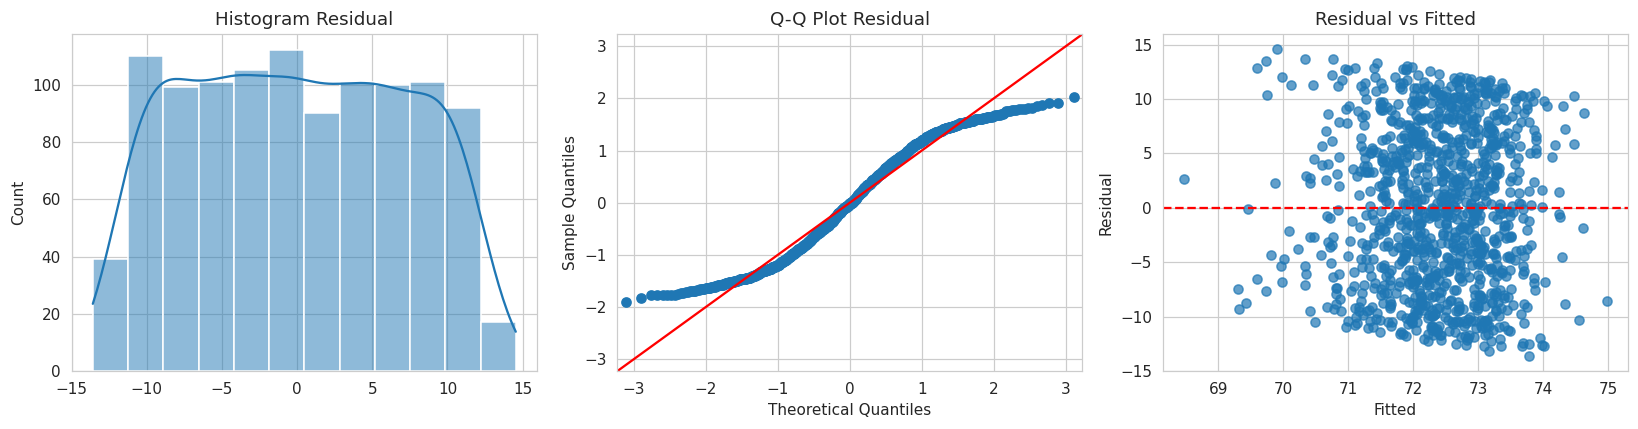

In [20]:
resid = model.resid

# 1) Normalitas
sh = stats.shapiro(resid)
ks = stats.kstest((resid - resid.mean())/resid.std(), "norm")
print(f"[Normalitas]  Shapiro-Wilk p = {sh.pvalue:.4f} | Kolmogorov-Smirnov p = {ks.pvalue:.4f} ->",
      "Normal" if sh.pvalue > ALPHA else "Tidak normal")

# 2) Multikolinearitas
vif = pd.DataFrame({"Variabel": X.columns,
                    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
vif = vif[vif.Variabel != "const"]
vif["Tolerance"] = 1 / vif["VIF"]
vif["Keterangan"] = np.where(vif["VIF"] < 10, "Bebas multikolinearitas", "Multikolinearitas")
print("\n[Multikolinearitas]"); display(vif.round(4))

# 3) Heteroskedastisitas
bp = het_breuschpagan(resid, model.model.exog)
print(f"[Heteroskedastisitas] Breusch-Pagan p = {bp[1]:.4f} ->",
      "Homoskedastis" if bp[1] > ALPHA else "Heteroskedastis")

# 4) Autokorelasi
dw = durbin_watson(resid)
print(f"[Autokorelasi] Durbin-Watson = {dw:.4f} (≈2 = tidak ada autokorelasi)")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(resid, kde=True, ax=ax[0]); ax[0].set_title("Histogram Residual")
sm.qqplot(resid, line="45", fit=True, ax=ax[1]); ax[1].set_title("Q-Q Plot Residual")
ax[2].scatter(model.fittedvalues, resid, alpha=.7); ax[2].axhline(0, color="red", ls="--")
ax[2].set_xlabel("Fitted"); ax[2].set_ylabel("Residual"); ax[2].set_title("Residual vs Fitted")
plt.tight_layout(); plt.savefig("asumsi_klasik.png"); plt.show()

## 8. Visualisasi 3D Interaktif (Plotly)
**Cara membaca grafik:**
- **Bidang berwarna** = hasil regresi (nilai Y yang diprediksi model untuk kombinasi dua X).
- **Titik-titik** = data asli. Secara default 1 titik = 1 kota (rata-rata 2014-2024), jadi hanya 97 titik. Arahkan kursor ke titik untuk melihat nama kota.
- Titik yang jauh dari bidang berarti model kurang pas untuk kota itu.
- **Mouse:** tekan dan geser untuk memutar, scroll untuk zoom. Tombol **Putar** menggerakkan grafik otomatis, dan ada tombol sudut pandang (Default, Atas, Depan, Samping).

Jika X lebih dari dua, X lain ditahan pada nilai rata-ratanya. Dua X yang ditampilkan adalah yang paling signifikan.

In [21]:
# ===== PENGATURAN TAMPILAN TITIK =====
TAMPIL = "rata-rata kota"     # "rata-rata kota" = 97 titik (rapi)  |  "semua" = semua 1.067 baris (padat)

urut = model.tvalues[X_COLS].abs().sort_values(ascending=False).index.tolist()
XA, XB = urut[0], urut[1]
print("Sumbu 3D -> X1:", XA, "| X2:", XB, "| Y:", Y_COL)

# data yang dipakai untuk titik (urutan sama dengan 'data')
ok = df[[Y_COL] + X_COLS].dropna().index
info = df.loc[ok].reset_index(drop=True)
if TAMPIL == "rata-rata kota" and "Kota" in info.columns:
    pl = info.groupby("Kota")[[Y_COL] + X_COLS].mean().reset_index()
    pl["label"] = pl["Kota"]
    ukuran, opasitas = 5, 0.95
else:
    pl = info.copy()
    pl["label"] = info["Kota"].astype(str) + " (" + info["Tahun"].astype(str) + ")" if "Kota" in info.columns else ""
    ukuran, opasitas = 2.5, 0.35
print("Jumlah titik ditampilkan:", len(pl))

def bidang_regresi(xa, xb, n=22):
    ga = np.linspace(data[xa].min(), data[xa].max(), n)
    gb = np.linspace(data[xb].min(), data[xb].max(), n)
    GA, GB = np.meshgrid(ga, gb)
    grid = pd.DataFrame({c: data[c].mean() for c in X_COLS}, index=range(GA.size))
    grid[xa] = GA.ravel(); grid[xb] = GB.ravel()
    Z = model.predict(sm.add_constant(grid[X_COLS], has_constant="add")).values.reshape(GA.shape)
    return GA, GB, Z

def buat_3d(xa, xb, judul=None, putar=True):
    GA, GB, Z = bidang_regresi(xa, xb)
    fig = go.Figure()
    fig.add_trace(go.Surface(x=GA, y=GB, z=Z, opacity=0.6, colorscale="Viridis",
                             colorbar=dict(title="Prediksi<br>"+Y_COL, x=1.0, len=0.6),
                             contours=dict(z=dict(show=True, usecolormap=True, project_z=True)),
                             name="Bidang regresi", hoverinfo="skip"))
    fig.add_trace(go.Scatter3d(
        x=pl[xa], y=pl[xb], z=pl[Y_COL], mode="markers", name="Data",
        marker=dict(size=ukuran, opacity=opasitas, color="crimson", line=dict(width=0.5, color="white")),
        text=pl["label"],
        hovertemplate="<b>%{text}</b><br>"+xa+": %{x:.1f}<br>"+xb+": %{y:.1f}<br>"+Y_COL+": %{z:.2f}<extra></extra>"))
    kam = lambda t: dict(eye=dict(x=2.1*np.cos(t), y=2.1*np.sin(t), z=0.9))
    fig.frames = [go.Frame(layout={"scene": {"camera": kam(t)}}) for t in np.linspace(0, 2*np.pi, 48)]
    preset = [("Default", dict(eye=dict(x=1.6, y=-1.6, z=1.0))), ("Atas", dict(eye=dict(x=0.01, y=0.01, z=2.6))),
              ("Depan", dict(eye=dict(x=0.01, y=-2.4, z=0.4))), ("Samping", dict(eye=dict(x=2.4, y=0.01, z=0.4)))]
    menus = [dict(type="buttons", direction="left", x=0.0, y=1.08, showactive=False, buttons=[
                dict(label="▶ Putar", method="animate",
                     args=[None, dict(frame=dict(duration=70, redraw=True), fromcurrent=True, transition=dict(duration=0))]),
                dict(label="⏸ Stop", method="animate",
                     args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate", transition=dict(duration=0))])]),
             dict(type="buttons", direction="left", x=0.35, y=1.08, showactive=False, buttons=[
                dict(label=n, method="relayout", args=[{"scene.camera": c}]) for n, c in preset])]
    fig.update_layout(
        title=judul or f"Regresi Berganda 3D: {Y_COL} ~ {xa} + {xb}",
        scene=dict(xaxis_title=xa, yaxis_title=xb, zaxis_title=Y_COL, camera=dict(eye=dict(x=1.6, y=-1.6, z=1.0))),
        updatemenus=menus if putar else [], width=950, height=720, margin=dict(l=0, r=0, t=70, b=0))
    return fig

fig3d = buat_3d(XA, XB)
fig3d.show()
fig3d.write_html("regresi_3d_interaktif.html")

Sumbu 3D -> X1: DBH_PAJAK | X2: bm_kesehatan | Y: IPM
Jumlah titik ditampilkan: 97


### 8.1 Permukaan Prediksi 3D + Peta Kontur

In [22]:
GA, GB, Z = bidang_regresi(XA, XB, n=40)
fig = go.Figure(go.Surface(x=GA, y=GB, z=Z, colorscale="Plasma",
                           contours=dict(z=dict(show=True, usecolormap=True, project_z=True)),
                           colorbar=dict(title="Prediksi<br>"+Y_COL)))
fig.update_layout(title=f"Permukaan Prediksi {Y_COL}", width=900, height=650, margin=dict(l=0, r=0, t=50, b=0),
                  scene=dict(xaxis_title=XA, yaxis_title=XB, zaxis_title=f"Prediksi {Y_COL}"))
fig.show(); fig.write_html("permukaan_prediksi.html")

fk = go.Figure(go.Contour(x=GA[0], y=GB[:, 0], z=Z, colorscale="Plasma", colorbar=dict(title="Prediksi<br>"+Y_COL)))
fk.add_trace(go.Scatter(x=pl[XA], y=pl[XB], mode="markers", name="Data",
                        marker=dict(size=5, color="white", line=dict(width=1, color="black")), text=pl["label"]))
fk.update_layout(title="Peta Kontur 2D (prediksi Y)", xaxis_title=XA, yaxis_title=XB, width=800, height=600)
fk.show()

### 8.2 3D untuk Semua Pasangan X

In [23]:
for a, b_ in list(combinations(X_COLS, 2))[:6]:
    f = buat_3d(a, b_, judul=f"{Y_COL} ~ {a} & {b_} (X lain di nilai rata-rata)")
    f.update_layout(width=850, height=620)
    f.show()
    f.write_html(f"regresi_3d_{a}_{b_}.html")

### 8.3 Aktual vs Prediksi

In [24]:
pred = model.fittedvalues
lim = [min(y.min(), pred.min()), max(y.max(), pred.max())]
fa = go.Figure()
fa.add_trace(go.Scatter(x=y, y=pred, mode="markers", name="Data", marker=dict(size=4, opacity=0.4)))
fa.add_trace(go.Scatter(x=lim, y=lim, mode="lines", name="Garis ideal", line=dict(color="red", dash="dash")))
fa.update_layout(title=f"Aktual vs Prediksi (R² = {model.rsquared:.3f})", xaxis_title="Aktual", yaxis_title="Prediksi",
                 width=650, height=550)
fa.show()

## 9. Model Robust (HC3) sebagai Pembanding

In [25]:
robust = sm.OLS(y, X).fit(cov_type="HC3")
pd.DataFrame({"Koef": robust.params, "Robust SE": robust.bse, "p-value": robust.pvalues}).round(4)

,Koef,Robust SE,p-value
const,74.2075,0.7248,0.0000
DBH_PAJAK,-0.0223,0.0072,0.0020
PAD,0.0087,0.0037,0.0198
bm_kesehatan,-0.0074,0.0030,0.0137


## 10. Kesimpulan Otomatis

In [26]:
print("=" * 70)
print("KESIMPULAN ANALISIS REGRESI LINIER BERGANDA")
print("=" * 70)
print(f"Variabel dependen (Y)    : {Y_COL}")
print(f"Variabel independen (X)  : {', '.join(X_COLS)}")
print(f"Jumlah observasi         : {len(data)}")
print(f"\nPersamaan: {persamaan}\n")
print(f"1) Uji F  : p = {model.f_pvalue:.4g} -> variabel X secara simultan",
      "BERPENGARUH signifikan" if model.f_pvalue < ALPHA else "TIDAK berpengaruh signifikan", f"terhadap {Y_COL}.")
print(f"2) R²     : Adj. R² = {model.rsquared_adj:.4f} -> {model.rsquared_adj*100:.2f}% variasi {Y_COL} dijelaskan oleh model.")
print("3) Uji t  :")
for c in X_COLS:
    arah = "positif" if model.params[c] > 0 else "negatif"
    sig = "signifikan" if model.pvalues[c] < ALPHA else "tidak signifikan"
    print(f"   - {c}: koef = {model.params[c]:.4f} (arah {arah}), p = {model.pvalues[c]:.4f} -> {sig}")
print("4) Asumsi klasik:")
print(f"   - Normalitas      : {'terpenuhi' if sh.pvalue > ALPHA else 'tidak terpenuhi'} (p = {sh.pvalue:.4f})")
print(f"   - Multikolinearitas: {'terpenuhi' if (vif.VIF < 10).all() else 'tidak terpenuhi'} (VIF maks = {vif.VIF.max():.2f})")
print(f"   - Heteroskedastisitas: {'terpenuhi' if bp[1] > ALPHA else 'tidak terpenuhi'} (p = {bp[1]:.4f})")
print(f"   - Autokorelasi    : DW = {dw:.4f}")
if model.rsquared < 0.10:
    print(f"\nCatatan: R² hanya {model.rsquared*100:.2f}%. Pengaruh X terhadap Y signifikan secara statistik, "
          "tetapi daya jelasnya sangat kecil (sebagian besar variasi Y dijelaskan faktor lain di luar model).")

KESIMPULAN ANALISIS REGRESI LINIER BERGANDA
Variabel dependen (Y)    : IPM
Variabel independen (X)  : DBH_PAJAK, PAD, bm_kesehatan
Jumlah observasi         : 1067

Persamaan: IPM = 74.2075 - 0.0223·DBH_PAJAK + 0.0087·PAD - 0.0074·bm_kesehatan

1) Uji F  : p = 0.0009336 -> variabel X secara simultan BERPENGARUH signifikan terhadap IPM.
2) R²     : Adj. R² = 0.0125 -> 1.25% variasi IPM dijelaskan oleh model.
3) Uji t  :
   - DBH_PAJAK: koef = -0.0223 (arah negatif), p = 0.0014 -> signifikan
   - PAD: koef = 0.0087 (arah positif), p = 0.0171 -> signifikan
   - bm_kesehatan: koef = -0.0074 (arah negatif), p = 0.0145 -> signifikan
4) Asumsi klasik:
   - Normalitas      : tidak terpenuhi (p = 0.0000)
   - Multikolinearitas: terpenuhi (VIF maks = 3.37)
   - Heteroskedastisitas: terpenuhi (p = 0.7600)
   - Autokorelasi    : DW = 2.0725

Catatan: R² hanya 1.53%. Pengaruh X terhadap Y signifikan secara statistik, tetapi daya jelasnya sangat kecil (sebagian besar variasi Y dijelaskan faktor lain 